# Hotel Bookings - Exploratory Data Analysis (EDA)
**Hotel Harmony: Data Insights for Optimized Operations**

**Prepared by:** Shubham Shah  
**Tools used:** Python, NumPy, Pandas, Matplotlib, Scikit-learn

## Project Overview
Elite Hotels International has hotels in different locations and wants to understand its booking patterns and guest behaviour. The management has asked for a data analysis of the booking data that can help them make better decisions on operations, pricing, marketing and guest experience.

**What I want to find out**
1. When do guests book and arrive, and which hotel and channels bring the most bookings?
2. Why do bookings get cancelled and how can cancellations be reduced?
3. How do price (ADR), guest type and special requests change from one group of guests to another?
4. What should management do based on these findings?

**Dataset:** Hotel Booking Demand (Kaggle) - `hotel_bookings.csv`  
Keep the csv file in the same folder as this notebook (or change the path in the load cell).

## Step 1: Import Libraries and Load the Data

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('hotel_bookings.csv')

## Step 2: Understanding the Data

In [7]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [8]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [9]:
df.shape

(119390, 32)

In [10]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [12]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


## Step 3: Data Cleaning
Order of cleaning: duplicates, missing values, dates, wrong values, new columns.

### 3.1 Removing duplicate rows

In [15]:
df.duplicated().sum()

31994

In [16]:
df = df.drop_duplicates().copy()
df.shape

(87396, 32)

### 3.2 Handling missing values

In [18]:
df.isnull().sum()[df.isnull().sum() > 0]

children        4
country       452
agent       12193
company     82137
dtype: int64

- **children**: only 4 rows are missing, so I fill them with 0 (no children).
- **country**: filled with 'Unknown'.
- **agent** and **company**: most rows are empty because the booking was **not** made through an agent or a company. So I fill them with 0, which means "no agent / no company".

In [20]:
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0).astype(int)
df['company'] = df['company'].fillna(0).astype(int)

In [21]:
df.isnull().sum().sum()

0

### 3.3 Converting date columns

In [23]:
# the month is given as a name, so first I convert it to a number
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
               'August', 'September', 'October', 'November', 'December']
month_number = {m: i + 1 for i, m in enumerate(month_order)}

df['arrival_month_no'] = df['arrival_date_month'].map(month_number)

# make one proper arrival date from year, month and day
df['arrival_date'] = pd.to_datetime(dict(year=df['arrival_date_year'],
                                         month=df['arrival_month_no'],
                                         day=df['arrival_date_day_of_month']))

df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

In [24]:
df[['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'arrival_date']].head()

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01


### 3.4 Checking wrong values
I checked `adr` (price per night) and the number of guests, because these should never be negative or zero in a real booking.

In [26]:
print('Negative ADR rows :', (df['adr'] < 0).sum())
print('Maximum ADR       :', df['adr'].max())
print('Bookings with no guests at all:', ((df['adults'] + df['children'] + df['babies']) == 0).sum())

Negative ADR rows : 1
Maximum ADR       : 5400.0
Bookings with no guests at all: 166


In [27]:
# one booking has a negative price and one has an ADR of 5400 (a clear mistake, normal price is under 500)
df = df[(df['adr'] >= 0) & (df['adr'] < 5000)]

# bookings with 0 adults, 0 children and 0 babies are not real bookings
df = df[(df['adults'] + df['children'] + df['babies']) > 0]
df.shape

(87228, 34)

Some bookings have an ADR of 0. I am keeping them because these are usually free or complimentary stays and not mistakes.

### 3.5 Creating new columns

In [30]:
# total nights stayed
df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

# total people in the booking
df['total_guests'] = df['adults'] + df['children'] + df['babies']

# revenue of a booking = price per night x number of nights
df['revenue'] = df['adr'] * df['total_stay']

In [31]:
df[['total_stay', 'total_guests', 'adr', 'revenue']].head()

,total_stay,total_guests,adr,revenue
0,0,2,0.0,0.0
1,0,2,0.0,0.0
2,1,1,75.0,75.0
3,1,1,75.0,75.0
4,2,2,98.0,196.0


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 87228 entries, 0 to 119389
Data columns (total 37 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87228 non-null  object        
 1   is_canceled                     87228 non-null  int64         
 2   lead_time                       87228 non-null  int64         
 3   arrival_date_year               87228 non-null  int64         
 4   arrival_date_month              87228 non-null  object        
 5   arrival_date_week_number        87228 non-null  int64         
 6   arrival_date_day_of_month       87228 non-null  int64         
 7   stays_in_weekend_nights         87228 non-null  int64         
 8   stays_in_week_nights            87228 non-null  int64         
 9   adults                          87228 non-null  int64         
 10  children                        87228 non-null  int32         
 11  babies

The data is clean now. We started with **119,390** rows and are left with **87,228** bookings to analyze. The data covers arrivals from **2015-07-01** to **2017-08-31**.

# Basic Level Questions

## Basic Q1. What is the average lead time for bookings?

In [36]:
avg_lead = df['lead_time'].mean()
print('Average lead time:', round(avg_lead, 1), 'days')
print('Median lead time :', df['lead_time'].median(), 'days')

Average lead time: 80.0 days
Median lead time : 49.0 days


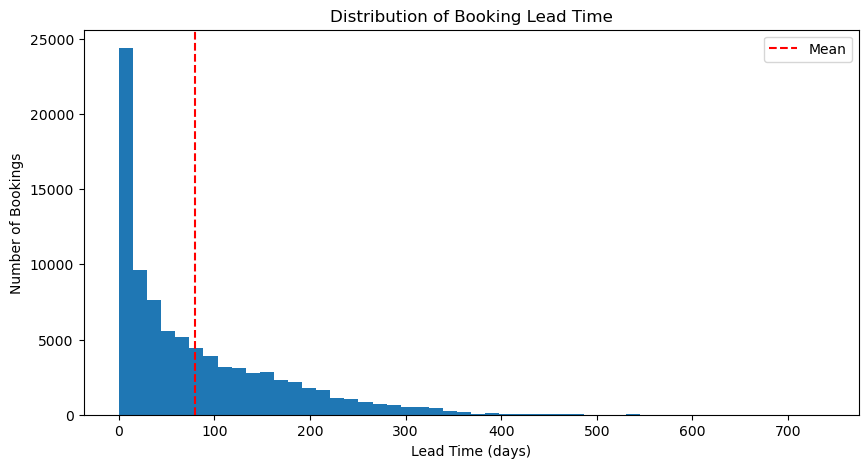

In [37]:
plt.figure(figsize=(10,5))
plt.hist(df['lead_time'], bins=50)
plt.axvline(avg_lead, color='red', linestyle='--', label='Mean')
plt.title('Distribution of Booking Lead Time')
plt.xlabel('Lead Time (days)')
plt.ylabel('Number of Bookings')
plt.legend()
plt.show()

**Insight:** Guests book on average **80 days** before arrival, but the median is only **49 days**. This means many guests book close to the arrival date and a smaller group books many months in advance, which pulls the average up. **40%** of bookings are made within 30 days of arrival, so last-minute campaigns are important.

## Basic Q2. What is the distribution of bookings by hotel type?

In [40]:
hotel_count = df['hotel'].value_counts()
hotel_count

hotel
City Hotel      53273
Resort Hotel    33955
Name: count, dtype: int64

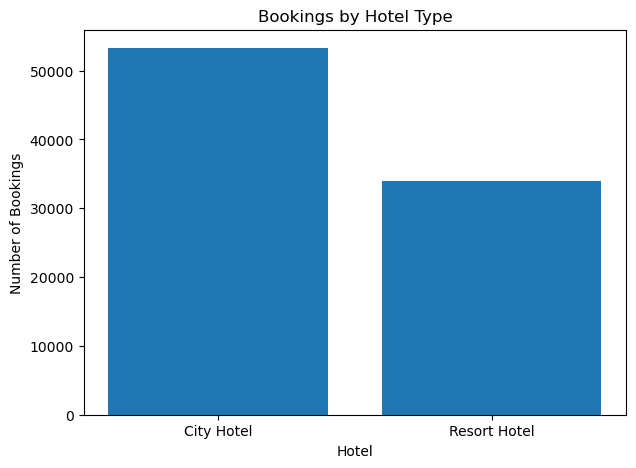

In [41]:
plt.figure(figsize=(7,5))
plt.bar(hotel_count.index, hotel_count.values)
plt.title('Bookings by Hotel Type')
plt.xlabel('Hotel')
plt.ylabel('Number of Bookings')
plt.show()

**Insight:** **City Hotel** gets **53,273** bookings (61%) and **Resort Hotel** gets 33,955 (39%). The city hotel is the more popular booking choice.

## Basic Q3. How many bookings were canceled?

In [44]:
canceled = df['is_canceled'].sum()
print('Canceled bookings:', canceled)
print('Cancellation percentage:', round(canceled / len(df) * 100, 1), '%')

Canceled bookings: 24008
Cancellation percentage: 27.5 %


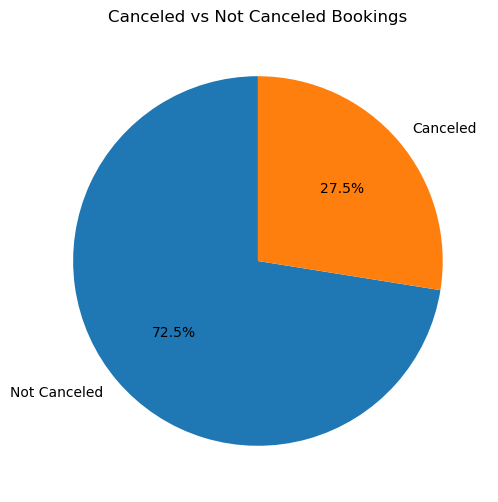

In [45]:
cancel_count = df['is_canceled'].value_counts().sort_index()

plt.figure(figsize=(6,6))
plt.pie(cancel_count.values, labels=['Not Canceled', 'Canceled'], autopct='%1.1f%%', startangle=90)
plt.title('Canceled vs Not Canceled Bookings')
plt.show()

**Insight:** **24,008 bookings** were canceled, which is **27.5%** - more than 1 in every 4 bookings. Each cancellation is a room that may stay empty, so reducing this number can directly increase revenue.

## Basic Q4. What is the most common arrival month for bookings?

In [48]:
print('Most common arrival month:', df['arrival_date_month'].mode()[0])
month_count = df['arrival_date_month'].value_counts().reindex(month_order)
month_count

Most common arrival month: August


arrival_date_month
January       4685
February      6083
March         7487
April         7900
May           8344
June          7756
July         10043
August       11242
September     6682
October       6921
November      4973
December      5112
Name: count, dtype: int64

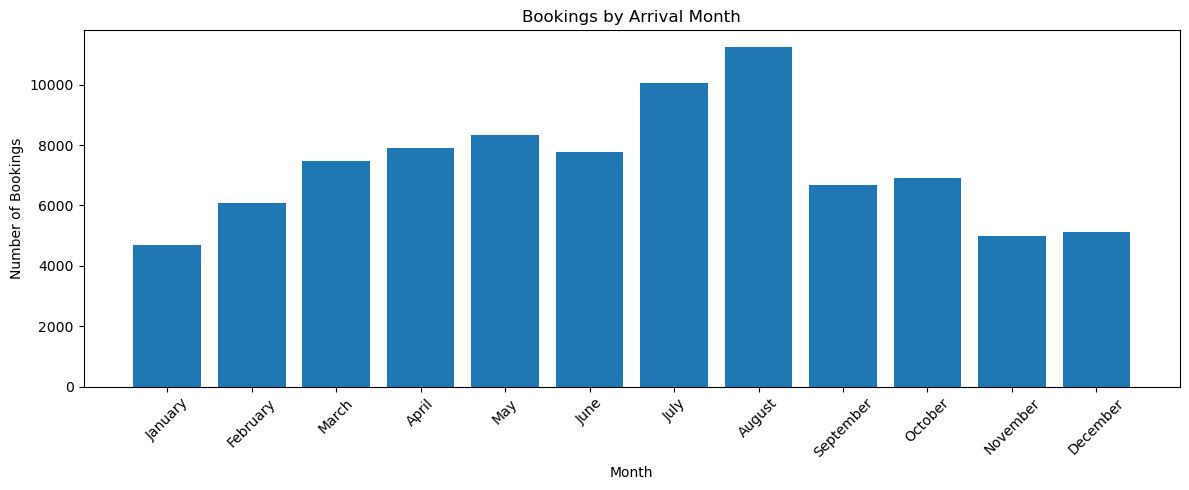

In [49]:
plt.figure(figsize=(12,5))
plt.bar(month_count.index, month_count.values)
plt.title('Bookings by Arrival Month')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The data runs from July 2015 to August 2017, so July and August are counted three times and the other months only two times. To be fair, I also check **2016**, which is the only full year in the data.

In [51]:
month_count_2016 = df[df['arrival_date_year'] == 2016]['arrival_date_month'].value_counts().reindex(month_order)
month_count_2016

arrival_date_month
January      1849
February     2799
March        3825
April        3767
May          3777
June         3515
July         3842
August       4415
September    3848
October      4227
November     3311
December     3137
Name: count, dtype: int64

**Insight:** **August** is the most common arrival month (11,242 bookings). Even in 2016 alone the busiest month is **August** (4,415) and the quietest is **January** (1,849). Summer is the peak season, and winter months are the slowest.

## Basic Q5. What is the average number of special requests per booking?

In [54]:
avg_requests = df['total_of_special_requests'].mean()
print('Average special requests per booking:', round(avg_requests, 2))
request_count = df['total_of_special_requests'].value_counts().sort_index()
request_count

Average special requests per booking: 0.7


total_of_special_requests
0    43787
1    28976
2    11795
3     2314
4      320
5       36
Name: count, dtype: int64

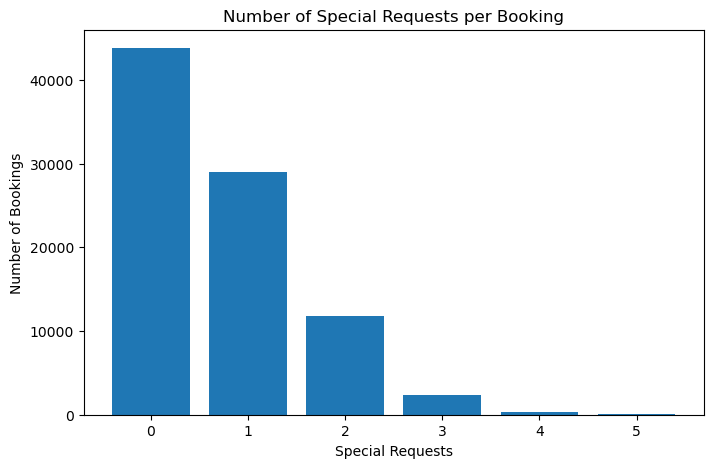

In [55]:
plt.figure(figsize=(8,5))
plt.bar(request_count.index.astype(str), request_count.values)
plt.title('Number of Special Requests per Booking')
plt.xlabel('Special Requests')
plt.ylabel('Number of Bookings')
plt.show()

**Insight:** On average each booking has **0.70** special requests. **50%** of bookings have no request at all, and only 17% have 2 or more. Customer service should be ready to handle requests like room type or floor preference for the guests who ask.

## Basic Q6. Which country has the highest number of bookings?

In [58]:
country_count = df['country'].value_counts()
country_count.head(10)

country
PRT    27354
GBR    10423
FRA     8823
ESP     7244
DEU     5385
ITA     3061
IRL     3015
BEL     2081
BRA     1993
NLD     1910
Name: count, dtype: int64

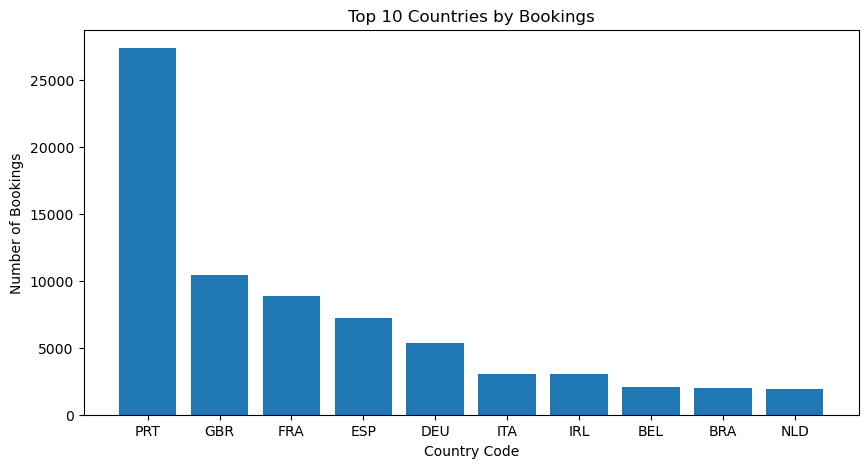

In [59]:
plt.figure(figsize=(10,5))
plt.bar(country_count.head(10).index, country_count.head(10).values)
plt.title('Top 10 Countries by Bookings')
plt.xlabel('Country Code')
plt.ylabel('Number of Bookings')
plt.show()

**Insight:** **PRT** (Portugal) has the most bookings with **27,354** (31% of all bookings), followed by GBR (United Kingdom) and FRA (France). The top 5 countries together make up 68% of all bookings, so marketing should focus on these key regions.

## Basic Q7. What is the average daily rate (ADR) for each hotel type?

In [62]:
adr_hotel = df.groupby('hotel')['adr'].mean()
adr_hotel

hotel
City Hotel      111.172693
Resort Hotel     99.062622
Name: adr, dtype: float64

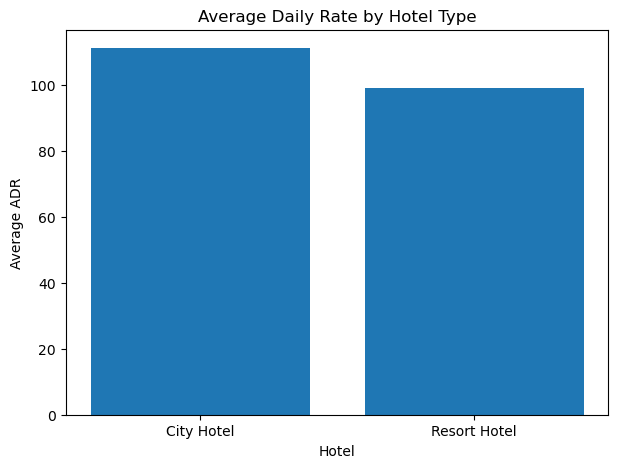

In [63]:
plt.figure(figsize=(7,5))
plt.bar(adr_hotel.index, adr_hotel.values)
plt.title('Average Daily Rate by Hotel Type')
plt.xlabel('Hotel')
plt.ylabel('Average ADR')
plt.show()

**Insight:** The average price per night is **111.17** at the City Hotel and **99.06** at the Resort Hotel. The city hotel earns more per night on average.

## Basic Q8. What percentage of guests required car parking spaces?

In [66]:
parking_pct = (df['required_car_parking_spaces'] > 0).mean() * 100
print('Bookings which needed parking:', round(parking_pct, 1), '%')

Bookings which needed parking: 8.4 %


**Insight:** Only **8.4%** of bookings needed a parking space. Most guests do not come by car (or do not book parking), so the hotels do not need a very large parking area, but a small number of spaces should always be available.

## Basic Q9. What is the average stay duration in week nights and weekend nights?

In [69]:
print('Average week nights   :', round(df['stays_in_week_nights'].mean(), 2))
print('Average weekend nights:', round(df['stays_in_weekend_nights'].mean(), 2))
print('Average total stay    :', round(df['total_stay'].mean(), 2))

Average week nights   : 2.62
Average weekend nights: 1.0
Average total stay    : 3.63


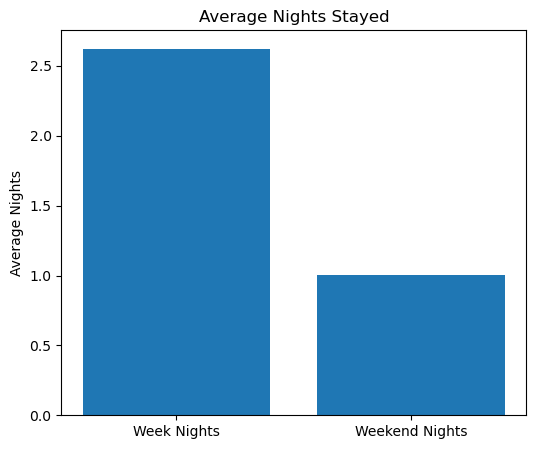

In [70]:
stay_avg = [df['stays_in_week_nights'].mean(), df['stays_in_weekend_nights'].mean()]

plt.figure(figsize=(6,5))
plt.bar(['Week Nights', 'Weekend Nights'], stay_avg)
plt.title('Average Nights Stayed')
plt.ylabel('Average Nights')
plt.show()

**Insight:** Guests stay on average **2.62 week nights** and **1.00 weekend nights**, which is about **3.6 nights** in total. Per day of the week it is almost the same: about 0.52 nights for each weekday and 0.50 for each weekend day, so guests stay evenly through the week. A typical stay is short, around 3 to 4 nights.

## Basic Q10. How many bookings were made through travel agents?

In [73]:
# agent = 0 means no agent was used (we filled the missing values with 0)
agent_bookings = (df['agent'] != 0).sum()
print('Bookings made through travel agents:', agent_bookings)
print('Percentage of all bookings:', round(agent_bookings / len(df) * 100, 1), '%')

Bookings made through travel agents: 75087
Percentage of all bookings: 86.1 %


**Insight:** **75,087 bookings (86%)** came through travel agents. Agents bring a big share of the guests, so the hotels should keep good relationships with them.

# Medium Level Questions

## Medium Q1. What is the cancellation rate for each hotel type?

In [77]:
cancel_hotel = df.groupby('hotel')['is_canceled'].mean() * 100
cancel_hotel

hotel
City Hotel      30.097798
Resort Hotel    23.484023
Name: is_canceled, dtype: float64

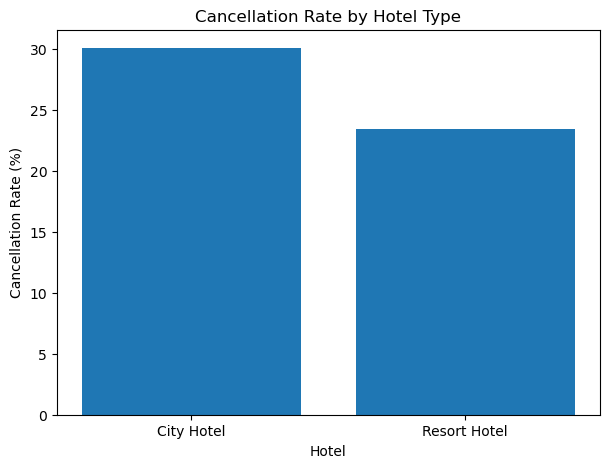

In [78]:
plt.figure(figsize=(7,5))
plt.bar(cancel_hotel.index, cancel_hotel.values)
plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel')
plt.ylabel('Cancellation Rate (%)')
plt.show()

**Insight:** The **City Hotel** has a cancellation rate of **30.1%** against **23.5%** for the **Resort Hotel**. City hotel bookings are cancelled more often, so the city hotel needs a stronger plan (like deposits or reconfirmation) to reduce cancellations.

## Medium Q2. What is the average ADR per market segment?

In [81]:
adr_segment = df.groupby('market_segment')['adr'].mean().sort_values(ascending=False)
adr_segment

market_segment
Online TA        118.296093
Direct           116.784056
Aviation         100.613628
Offline TA/TO     81.565033
Groups            75.184371
Corporate         68.344298
Undefined         15.000000
Complementary      3.093309
Name: adr, dtype: float64

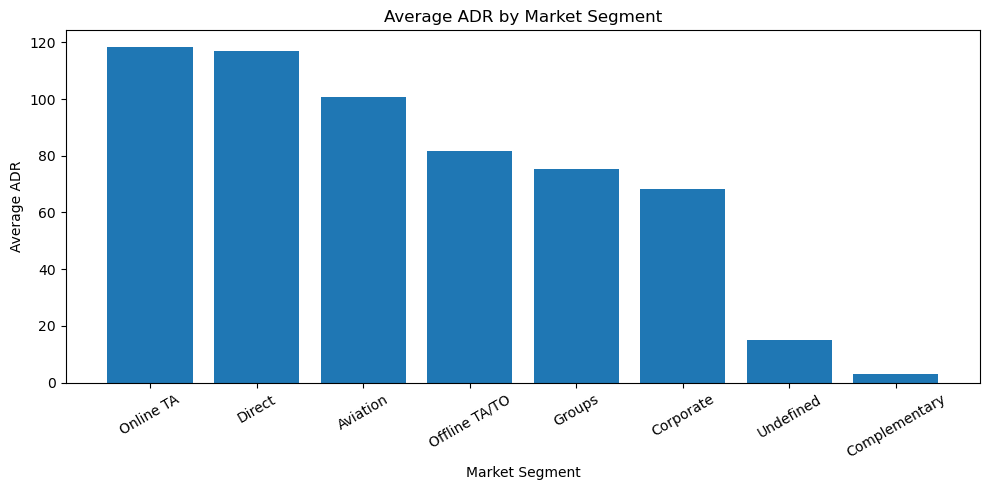

In [82]:
plt.figure(figsize=(10,5))
plt.bar(adr_segment.index, adr_segment.values)
plt.title('Average ADR by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Average ADR')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Insight:** **Online TA** guests pay the highest price (118.30), followed by Direct (116.78). The lowest are **Complementary** (3.09) and Undefined (15.00). Complementary stays have a very low price because they are mostly free or discounted.

## Medium Q3. What is the relationship between lead time and cancellation rate?

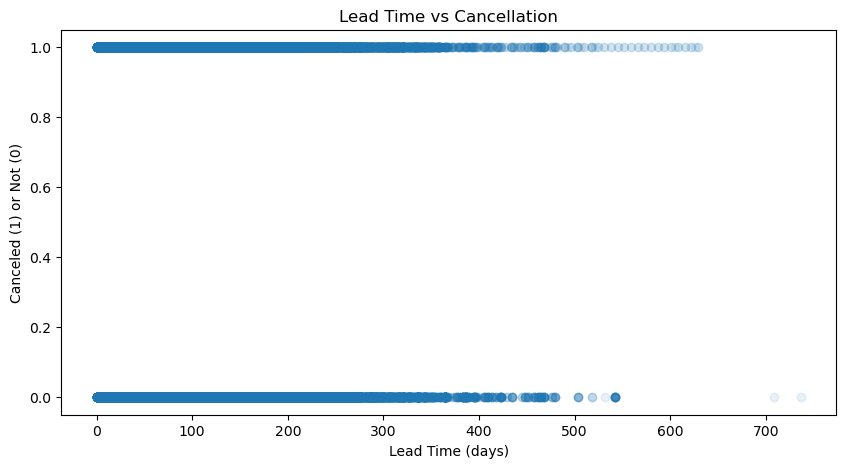

In [85]:
plt.figure(figsize=(10,5))
plt.scatter(df['lead_time'], df['is_canceled'], alpha=0.1)
plt.title('Lead Time vs Cancellation')
plt.xlabel('Lead Time (days)')
plt.ylabel('Canceled (1) or Not (0)')
plt.show()

A scatter plot with only 0 and 1 on one axis is hard to read, so I also group the lead time into bands and check the cancellation rate of each band.

In [87]:
print('Correlation between lead time and cancellation:', round(df['lead_time'].corr(df['is_canceled']), 3))

df['lead_band'] = pd.cut(df['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 800],
                         labels=['0-7 days', '8-30 days', '31-90 days', '91-180 days', '181-365 days', '365+ days'])
cancel_lead = df.groupby('lead_band', observed=True)['is_canceled'].mean() * 100
cancel_lead

Correlation between lead time and cancellation: 0.185


lead_band
0-7 days         8.416195
8-30 days       25.388950
31-90 days      32.039262
91-180 days     35.008780
181-365 days    39.689064
365+ days       40.780142
Name: is_canceled, dtype: float64

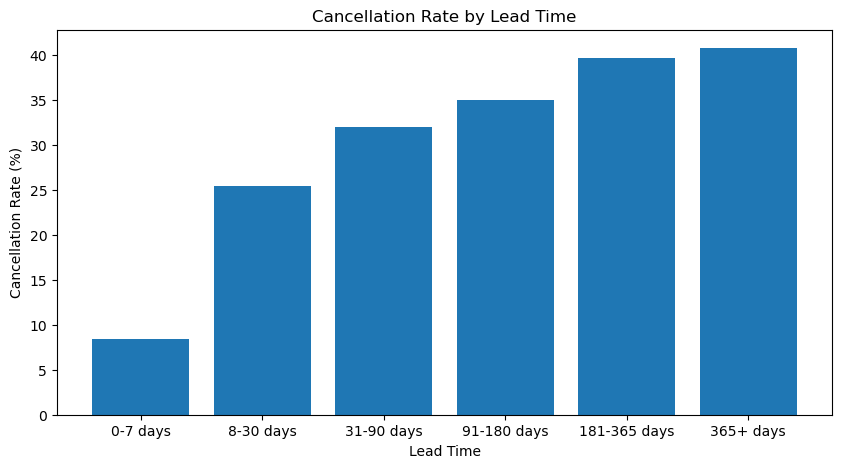

In [88]:
plt.figure(figsize=(10,5))
plt.bar(cancel_lead.index.astype(str), cancel_lead.values)
plt.title('Cancellation Rate by Lead Time')
plt.xlabel('Lead Time')
plt.ylabel('Cancellation Rate (%)')
plt.show()

**Insight:** Longer lead time means more cancellations. The correlation is **0.18**, which is a positive but modest link. Bookings made within a week are cancelled only **8%** of the time, while bookings made more than a year ahead are cancelled **41%** of the time. People who book far ahead have more time to change their plans.

## Medium Q4. Which distribution channel has the highest number of bookings?

In [91]:
channel_count = df['distribution_channel'].value_counts()
channel_count

distribution_channel
TA/TO        69027
Direct       12953
Corporate     5062
GDS            181
Undefined        5
Name: count, dtype: int64

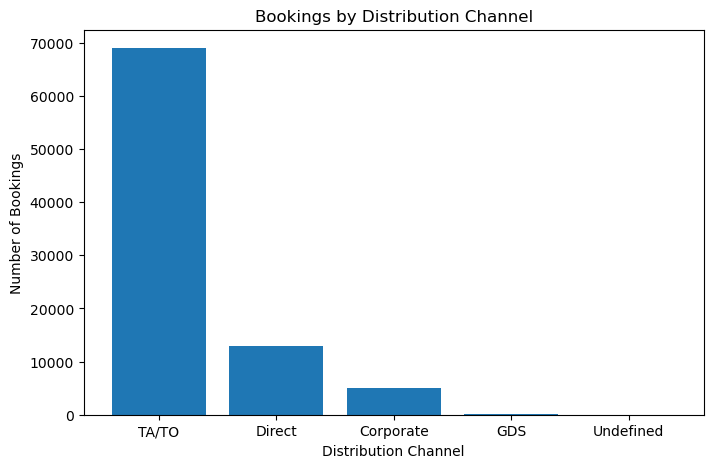

In [92]:
plt.figure(figsize=(8,5))
plt.bar(channel_count.index, channel_count.values)
plt.title('Bookings by Distribution Channel')
plt.xlabel('Distribution Channel')
plt.ylabel('Number of Bookings')
plt.show()

**Insight:** **TA/TO** (travel agents and tour operators) is the biggest channel with **69,027** bookings (79%), followed by Direct (12,953). Very few bookings come through GDS (only 181, which is 0.2%), so it is not worth spending much effort there.

## Medium Q5. What is the average number of previous cancellations by hotel type?

In [95]:
prev_cancel = df.groupby('hotel')['previous_cancellations'].mean()
prev_cancel

hotel
City Hotel      0.035759
Resort Hotel    0.022000
Name: previous_cancellations, dtype: float64

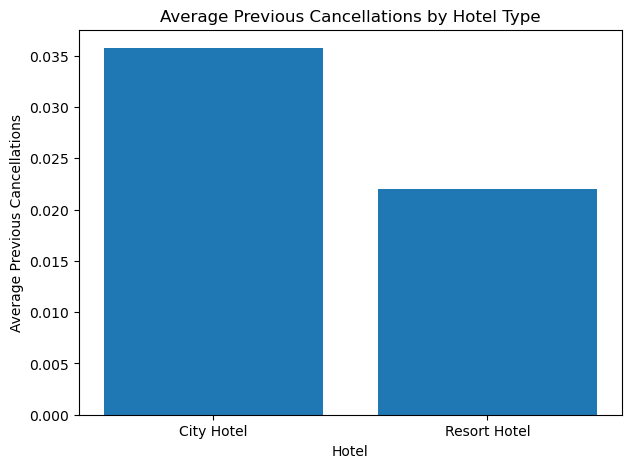

In [96]:
plt.figure(figsize=(7,5))
plt.bar(prev_cancel.index, prev_cancel.values)
plt.title('Average Previous Cancellations by Hotel Type')
plt.xlabel('Hotel')
plt.ylabel('Average Previous Cancellations')
plt.show()

**Insight:** The average is very small for both hotels - 0.036 for the City Hotel and 0.022 for the Resort Hotel - because most guests have never cancelled before. Only **1.9%** of bookings are from guests who cancelled in the past, so the past behaviour is not a big issue for either hotel.

## Medium Q6. What is the trend of ADR over the years?

In [99]:
adr_year = df.groupby('arrival_date_year')['adr'].mean()
adr_year

arrival_date_year
2015     92.361494
2016    101.571796
2017    118.915600
Name: adr, dtype: float64

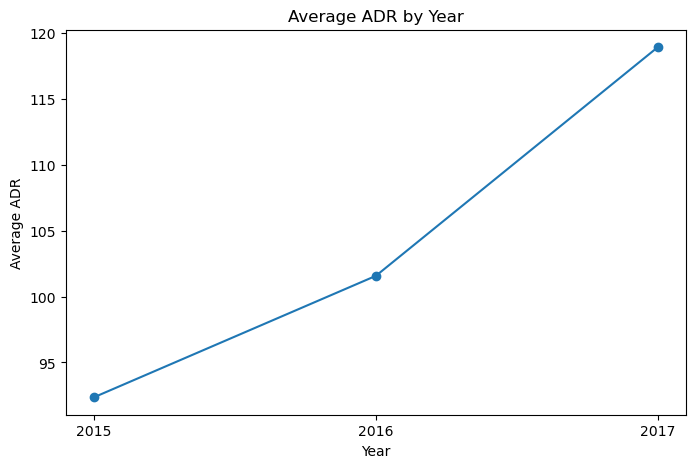

In [100]:
plt.figure(figsize=(8,5))
plt.plot(adr_year.index.astype(str), adr_year.values, marker='o')
plt.title('Average ADR by Year')
plt.xlabel('Year')
plt.ylabel('Average ADR')
plt.show()

2015 only has July to December and 2017 only has January to August, so the yearly average is not a fair comparison. I also check the monthly trend and the same months (July and August) in all 3 years.

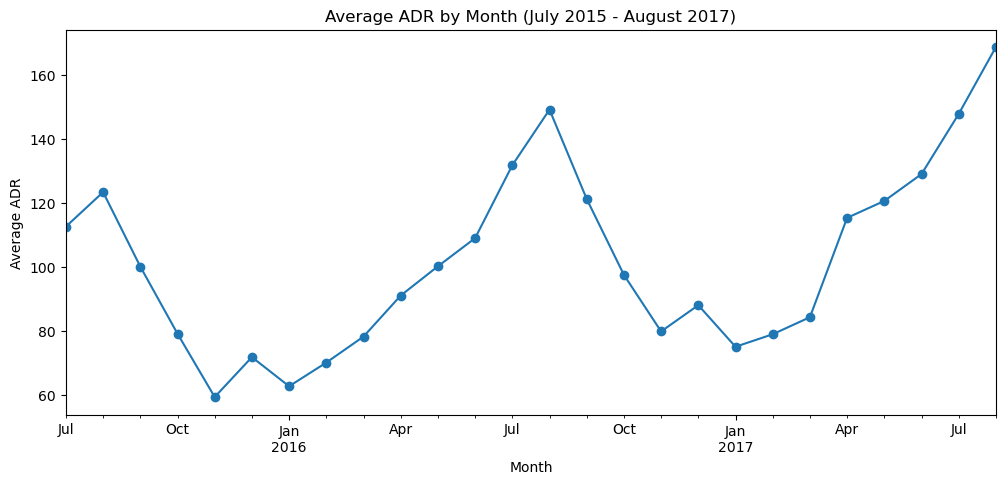

In [102]:
adr_monthly = df.groupby(df['arrival_date'].dt.to_period('M'))['adr'].mean()

plt.figure(figsize=(12,5))
adr_monthly.plot(marker='o')
plt.title('Average ADR by Month (July 2015 - August 2017)')
plt.xlabel('Month')
plt.ylabel('Average ADR')
plt.show()

In [103]:
# only July and August, which exist in all 3 years
summer_adr = df[df['arrival_date_month'].isin(['July', 'August'])].groupby('arrival_date_year')['adr'].mean()
summer_adr

arrival_date_year
2015    118.927361
2016    140.968034
2017    157.963925
Name: adr, dtype: float64

**Insight:** The yearly average goes from 92 (2015) to 102 (2016) to 119 (2017). For a fair comparison, July-August prices were 119 in 2015, 141 in 2016 and 158 in 2017, so the price has been **going up every year**. The monthly chart also shows a clear seasonal pattern: prices rise in summer and fall in winter.

## Medium Q7. Which month has the highest revenue?

Revenue = ADR x nights stayed. I only count bookings that were **not canceled**, because canceled bookings did not bring money.

In [107]:
completed = df[df['is_canceled'] == 0]
revenue_month = completed.groupby('arrival_date_month')['revenue'].sum().reindex(month_order)
revenue_month

arrival_date_month
January       705019.55
February     1024202.26
March        1415734.71
April        1804556.70
May          2059809.09
June         2295647.03
July         3798500.20
August       4606618.30
September    1969859.31
October      1476094.71
November      891885.64
December      919684.45
Name: revenue, dtype: float64

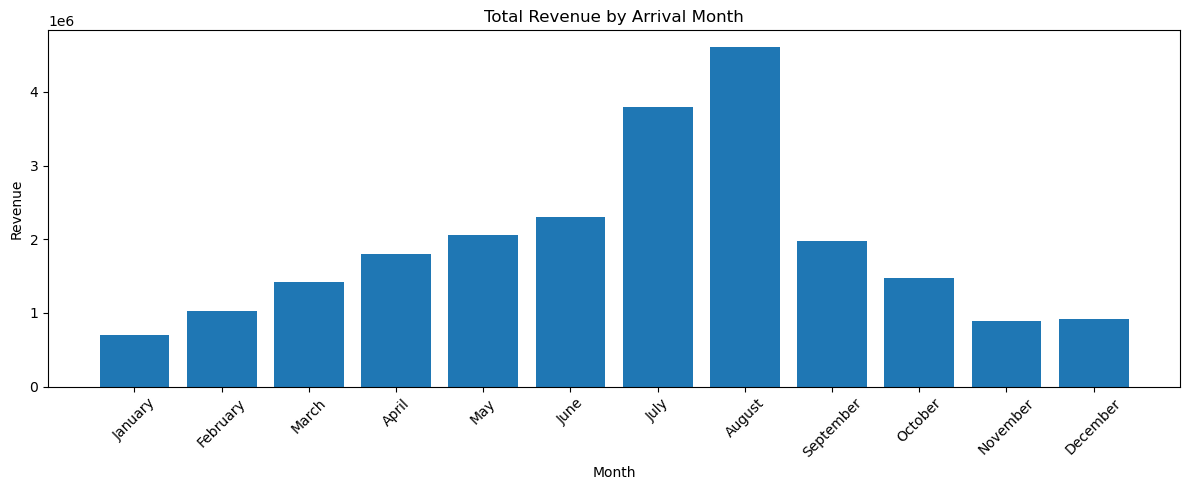

In [108]:
plt.figure(figsize=(12,5))
plt.bar(revenue_month.index, revenue_month.values)
plt.title('Total Revenue by Arrival Month')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [109]:
# the same check as in the hint (sum of ADR) and the check using only 2016
print('Month with highest summed ADR:', df.groupby('arrival_date_month')['adr'].sum().idxmax())

revenue_2016 = completed[completed['arrival_date_year'] == 2016].groupby('arrival_date_month')['revenue'].sum()
print('Month with highest revenue in 2016 only:', revenue_2016.idxmax())

Month with highest summed ADR: August
Month with highest revenue in 2016 only: August


**Insight:** **August** has the highest revenue (4,606,618), then July. The result is the same when I use only 2016 (August), so it is not just because July and August appear in 3 years. The weakest month is **January**. Promotions should be planned for the slow winter months, and staff and rooms should be ready for the summer peak.

## Medium Q8. What is the impact of special requests on ADR?

In [112]:
print('Correlation between special requests and ADR:', round(df['total_of_special_requests'].corr(df['adr']), 3))
adr_requests = df.groupby('total_of_special_requests')['adr'].mean()
adr_requests

Correlation between special requests and ADR: 0.146


total_of_special_requests
0     99.768260
1    109.785310
2    118.699924
3    125.232939
4    131.088687
5    129.980000
Name: adr, dtype: float64

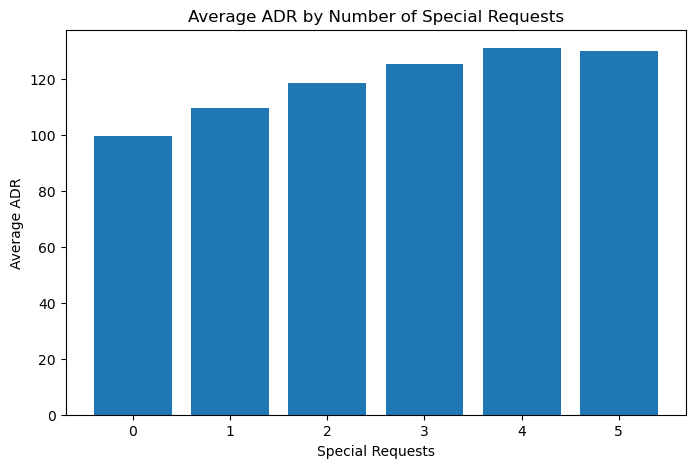

In [113]:
plt.figure(figsize=(8,5))
plt.bar(adr_requests.index.astype(str), adr_requests.values)
plt.title('Average ADR by Number of Special Requests')
plt.xlabel('Special Requests')
plt.ylabel('Average ADR')
plt.show()

**Insight:** Guests who make more special requests tend to pay a higher price - ADR goes from **100** with no request to **125** with 3 requests. The correlation is small (**0.15**), so it is a weak link, but guests who ask for special services are probably taking better rooms or travelling in the peak season.

## Medium Q9. What is the average stay duration for repeated guests versus new guests?

In [116]:
stay_repeat = df.groupby('is_repeated_guest')['total_stay'].mean()
stay_repeat.index = ['New Guest', 'Repeated Guest']
print(stay_repeat)

# extra check: do repeated guests cancel less?
cancel_repeat = df.groupby('is_repeated_guest')['is_canceled'].mean() * 100
print()
print('Cancellation rate (%) - new guests    :', round(cancel_repeat[0], 1))
print('Cancellation rate (%) - repeated guests:', round(cancel_repeat[1], 1))

New Guest         3.695797
Repeated Guest    1.950045
Name: total_stay, dtype: float64

Cancellation rate (%) - new guests    : 28.3
Cancellation rate (%) - repeated guests: 7.7


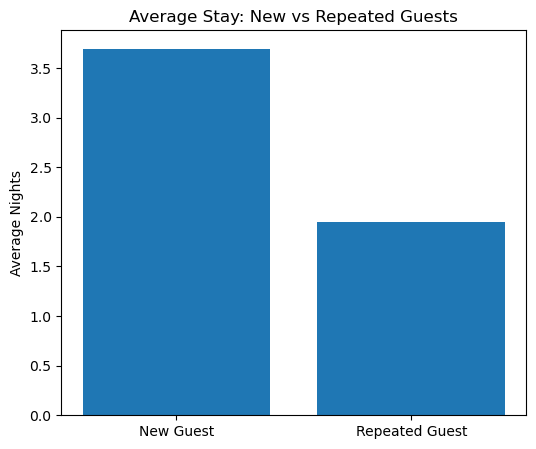

In [117]:
plt.figure(figsize=(6,5))
plt.bar(stay_repeat.index, stay_repeat.values)
plt.title('Average Stay: New vs Repeated Guests')
plt.ylabel('Average Nights')
plt.show()

**Insight:** New guests stay **3.70 nights** on average and repeated guests stay **1.95 nights**. Repeated guests stay shorter, and they are only **3.9%** of all bookings, which means the hotels have a very small base of returning guests. They are also much more reliable - only **7.7%** of repeated guests cancel against **28.3%** of new guests. A loyalty programme could help here.

## Medium Q10. Which room type has the highest number of bookings?

In [120]:
room_count = df['reserved_room_type'].value_counts()
room_count

reserved_room_type
A    56434
D    17376
E     6036
F     2820
G     2050
B      996
C      914
H      596
L        6
Name: count, dtype: int64

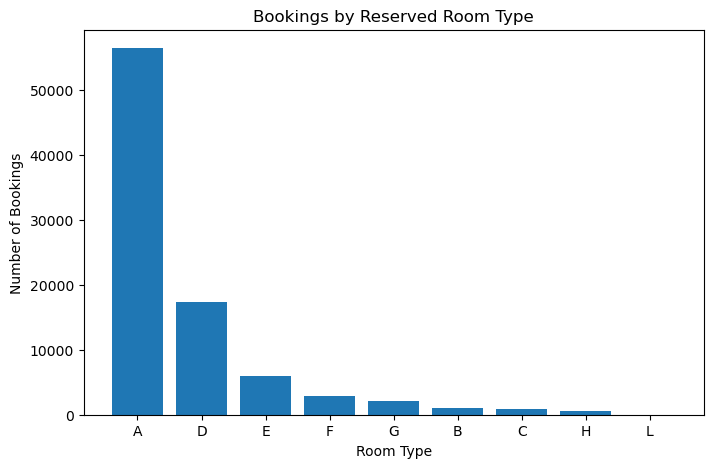

In [121]:
plt.figure(figsize=(8,5))
plt.bar(room_count.index, room_count.values)
plt.title('Bookings by Reserved Room Type')
plt.xlabel('Room Type')
plt.ylabel('Number of Bookings')
plt.show()

**Insight:** Room type **A** is booked the most with **56,434** bookings (65%), followed by room type D (17,376) and E (6,036). Most guests ask for room type A, so the hotels should keep enough of these rooms available.

# Advanced Level Questions

## Advanced Q1. What factors significantly impact the cancellation rate?

I use a **logistic regression** model to find which factors push a booking towards cancellation. I standardize the features first so that the coefficients can be compared with each other. A positive coefficient means more chance of cancellation, a negative one means less chance.

In [126]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

features = ['lead_time', 'previous_cancellations', 'booking_changes', 'total_of_special_requests',
            'required_car_parking_spaces', 'is_repeated_guest', 'days_in_waiting_list',
            'adr', 'total_stay', 'total_guests']

X = df[features]
y = df['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print('Accuracy on test data:', round(model.score(X_test, y_test), 3))

Accuracy on test data: 0.748


In [127]:
coefficients = pd.Series(model.coef_[0], index=features).sort_values()
coefficients

required_car_parking_spaces   -2.447309
total_of_special_requests     -0.387904
booking_changes               -0.321811
is_repeated_guest             -0.285622
days_in_waiting_list          -0.044865
total_stay                     0.060414
total_guests                   0.093553
previous_cancellations         0.364223
adr                            0.365987
lead_time                      0.377133
dtype: float64

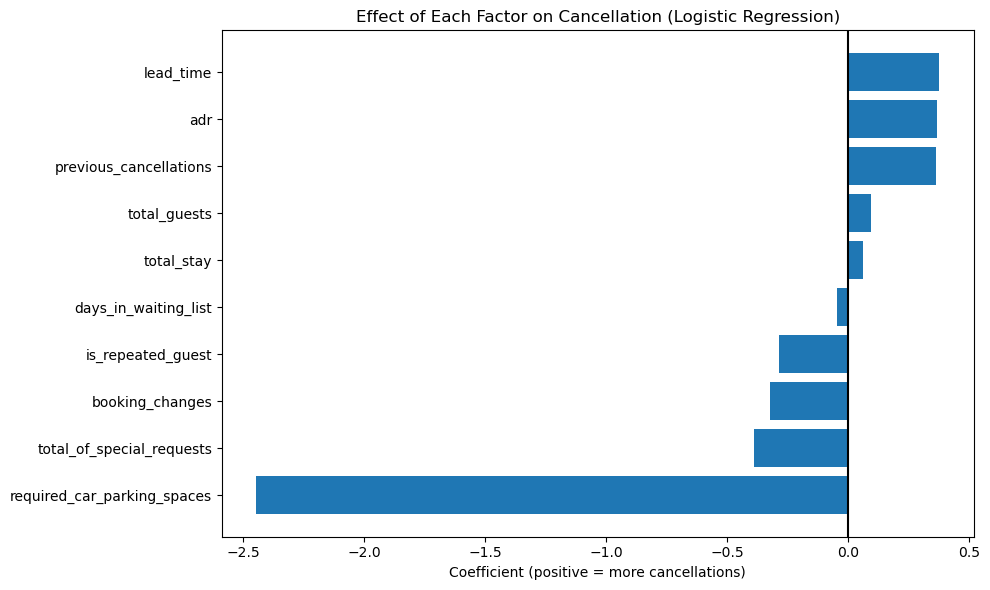

In [128]:
plt.figure(figsize=(10,6))
plt.barh(coefficients.index, coefficients.values)
plt.axvline(0, color='black')
plt.title('Effect of Each Factor on Cancellation (Logistic Regression)')
plt.xlabel('Coefficient (positive = more cancellations)')
plt.tight_layout()
plt.show()

In [129]:
# deposit type is text, so I look at it separately
df.groupby('deposit_type')['is_canceled'].agg(['mean', 'count'])

,mean,count
deposit_type,,
No Deposit,0.267181,86084
Non Refund,0.946962,1037
Refundable,0.242991,107


**Insight:** The model is **75% accurate** on test data. The factors that increase cancellation are **lead_time**, **adr** and **previous_cancellations** - in simple words, bookings made far in advance, bookings with a higher price and guests who cancelled before are more likely to be cancelled. The factors that reduce cancellation most are **required_car_parking_spaces** (by far the strongest), **total_of_special_requests**, **booking_changes** and **is_repeated_guest**. So guests who need parking, ask for special requests, change their booking or are repeat guests are more committed to the stay. Length of stay and the number of guests have very little effect. Also, the deposit data shows an odd result - 'Non Refund' bookings have a cancellation rate of **95%**. This should be checked by the management, because it may mean the non-refundable deposits are not stopping guests from cancelling, or that the deposit type is recorded wrongly.

## Advanced Q2. How does the ADR vary with the number of adults, children and babies?

In [132]:
# a few bookings have a very large number of guests (like 55 adults), so I only use normal bookings for the regression
normal = df[(df['adults'] <= 4) & (df['children'] <= 3) & (df['babies'] <= 2)]

from sklearn.linear_model import LinearRegression

X2 = normal[['adults', 'children', 'babies']]
y2 = normal['adr']

reg = LinearRegression()
reg.fit(X2, y2)

print('Intercept:', round(reg.intercept_, 2))
print(pd.Series(reg.coef_, index=['adults', 'children', 'babies']).round(2))
print('R-squared:', round(reg.score(X2, y2), 3))

Intercept: 38.99
adults      33.11
children    38.36
babies       6.56
dtype: float64
R-squared: 0.224


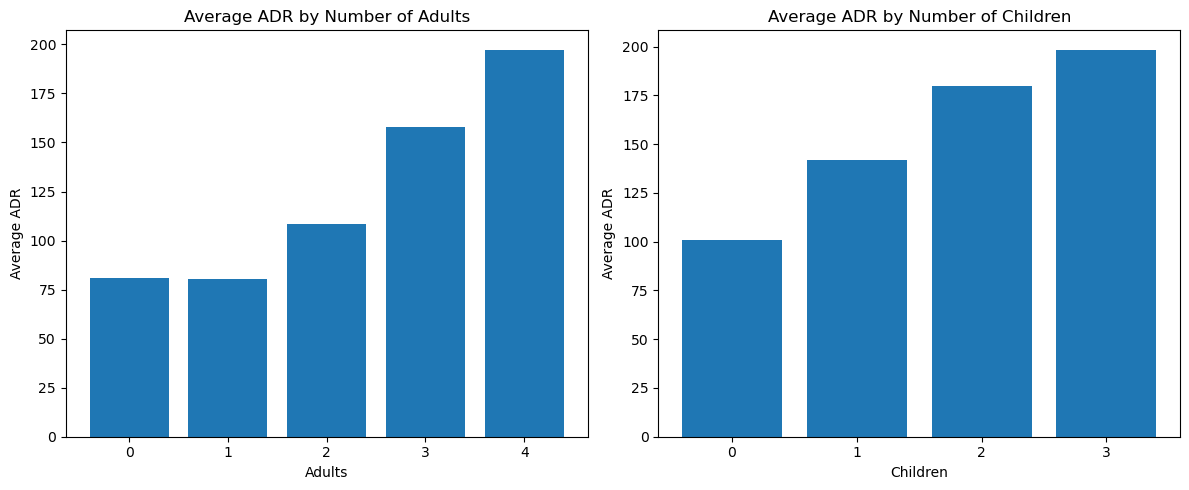

In [133]:
adr_children = normal.groupby('children')['adr'].mean()
adr_adults = normal.groupby('adults')['adr'].mean()

fig, ax = plt.subplots(1, 2, figsize=(12,5))
ax[0].bar(adr_adults.index.astype(str), adr_adults.values)
ax[0].set_title('Average ADR by Number of Adults')
ax[0].set_xlabel('Adults')
ax[0].set_ylabel('Average ADR')
ax[1].bar(adr_children.index.astype(str), adr_children.values)
ax[1].set_title('Average ADR by Number of Children')
ax[1].set_xlabel('Children')
ax[1].set_ylabel('Average ADR')
plt.tight_layout()
plt.show()

**Insight:** Each extra adult adds about **33** to the nightly price and each extra child adds about **38**. Each baby adds only about 7, a small effect. The R-squared is only **0.22**, so guest numbers explain a small part of the price - season, hotel type and room type matter more. Still, families with children are worth targeting with family packages because they pay a higher rate.

## Advanced Q3. What is the impact of booking changes on guest satisfaction (special requests)?

There is no satisfaction score in this data, so as the case study says, I use the number of special requests as a measure of how involved and engaged the guest is.

In [137]:
print('Correlation between booking changes and special requests:',
      round(df['booking_changes'].corr(df['total_of_special_requests']), 3))

# 4 and above changes are grouped together because they are very rare
changes = df['booking_changes'].clip(upper=4)
requests_by_changes = df.groupby(changes)['total_of_special_requests'].mean()
requests_by_changes

Correlation between booking changes and special requests: 0.018


booking_changes
0    0.696717
1    0.682525
2    0.737507
3    0.835267
4    0.844595
Name: total_of_special_requests, dtype: float64

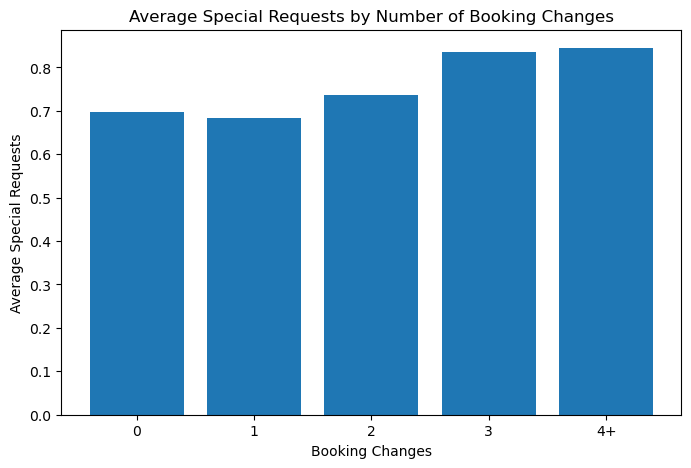

In [138]:
plt.figure(figsize=(8,5))
plt.bar(['0', '1', '2', '3', '4+'], requests_by_changes.values)
plt.title('Average Special Requests by Number of Booking Changes')
plt.xlabel('Booking Changes')
plt.ylabel('Average Special Requests')
plt.show()

**Insight:** Overall the correlation is only **0.02**, a very weak link, because most bookings have no change at all. Bookings with 0 or 1 change have about the same number of special requests (0.70 and 0.68), while guests who changed their booking 3 or more times make a few more requests (0.84 and 0.84). So changing a booking does not look like a sign of an unhappy guest - those guests are just a little more engaged with their stay. Easy booking changes should be allowed, since they do not seem to hurt the guest experience.

## Advanced Q4. What is the seasonal impact on booking cancellations?

In [141]:
cancel_month = df.groupby('arrival_date_month')['is_canceled'].mean().reindex(month_order) * 100
cancel_month

arrival_date_month
January      22.134472
February     23.212231
March        24.415654
April        30.455696
May          29.266539
June         30.337803
July         31.823160
August       32.218466
September    24.558515
October      23.724895
November     21.154233
December     26.936620
Name: is_canceled, dtype: float64

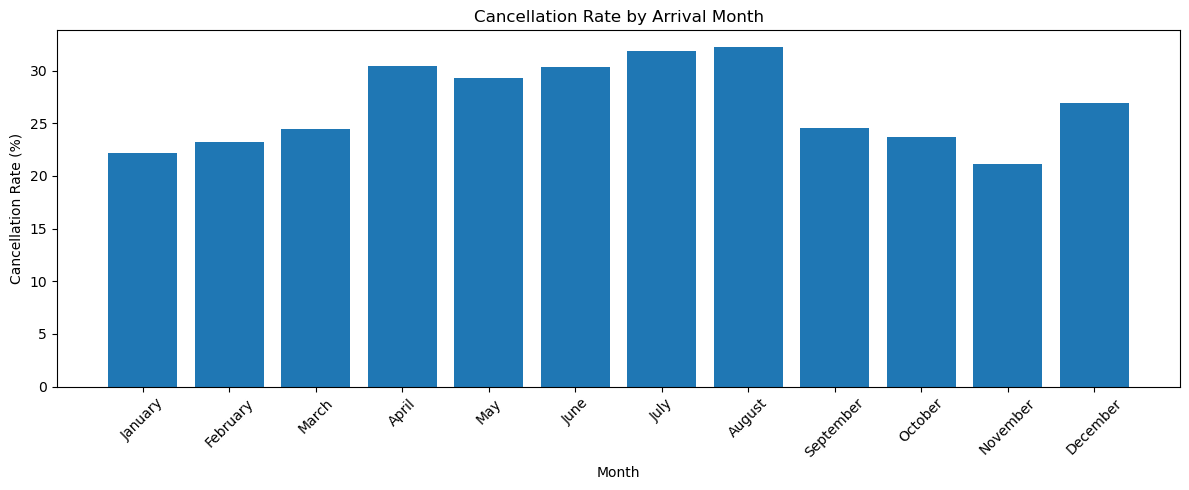

In [142]:
plt.figure(figsize=(12,5))
plt.bar(cancel_month.index, cancel_month.values)
plt.title('Cancellation Rate by Arrival Month')
plt.xlabel('Month')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [143]:
# grouping the months into seasons
season_map = {'December': 'Winter', 'January': 'Winter', 'February': 'Winter',
              'March': 'Spring', 'April': 'Spring', 'May': 'Spring',
              'June': 'Summer', 'July': 'Summer', 'August': 'Summer',
              'September': 'Autumn', 'October': 'Autumn', 'November': 'Autumn'}
df['season'] = df['arrival_date_month'].map(season_map)

cancel_season = df.groupby('season')['is_canceled'].mean().reindex(['Winter', 'Spring', 'Summer', 'Autumn']) * 100
cancel_season

season
Winter    24.093199
Spring    28.131979
Summer    31.579491
Autumn    23.336563
Name: is_canceled, dtype: float64

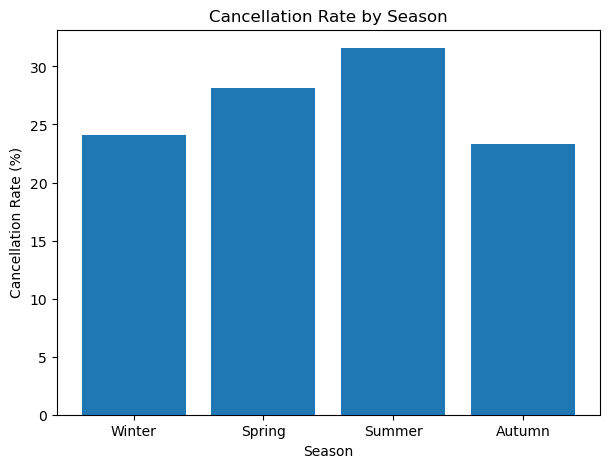

In [144]:
plt.figure(figsize=(7,5))
plt.bar(cancel_season.index, cancel_season.values)
plt.title('Cancellation Rate by Season')
plt.xlabel('Season')
plt.ylabel('Cancellation Rate (%)')
plt.show()

**Insight:** The cancellation rate is highest in **August** (32.2%) and lowest in **November** (21.2%). By season, **Summer** has the most cancellations (31.6%) and **Autumn** the fewest (23.3%). The difference is not huge, but it means the busy months are also the months when more rooms may get empty, so careful overbooking and reconfirmation calls matter most then.

## Advanced Q5. How does the booking lead time vary between market segments?

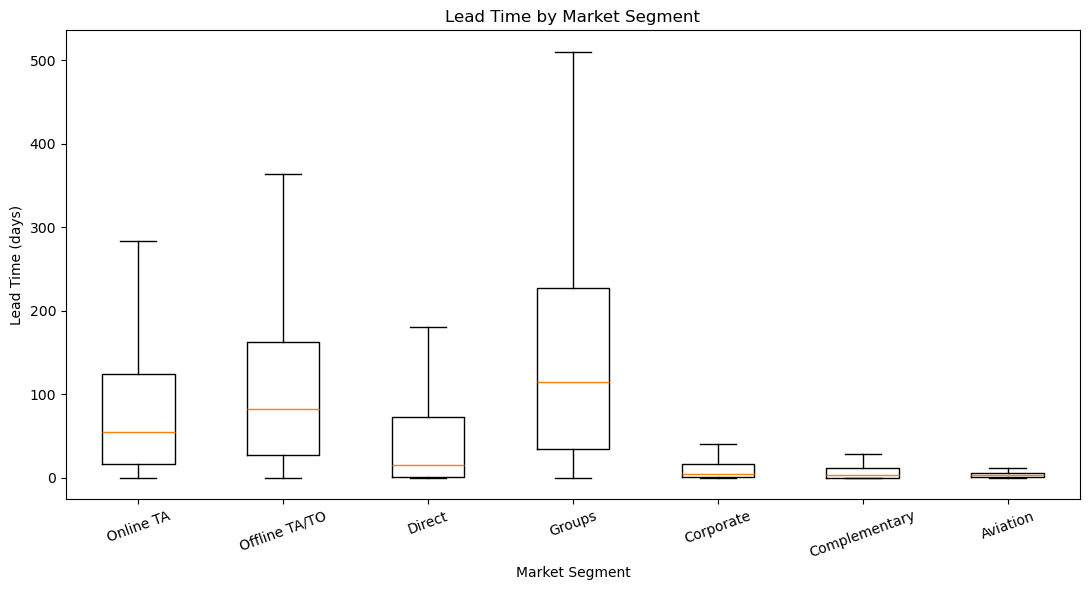

In [147]:
# only segments with enough bookings
seg_count = df['market_segment'].value_counts()
segments = seg_count[seg_count > 100].index.tolist()

lead_data = [df[df['market_segment'] == s]['lead_time'] for s in segments]

plt.figure(figsize=(11,6))
plt.boxplot(lead_data, showfliers=False)
plt.xticks(range(1, len(segments) + 1), segments, rotation=20)
plt.title('Lead Time by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Lead Time (days)')
plt.tight_layout()
plt.show()

In [148]:
lead_segment = df[df['market_segment'].isin(segments)].groupby('market_segment')['lead_time'].median().sort_values(ascending=False)
lead_segment

market_segment
Groups           115.0
Offline TA/TO     82.0
Online TA         55.0
Direct            15.0
Corporate          5.0
Aviation           3.0
Complementary      3.0
Name: lead_time, dtype: float64

**Insight:** **Groups** book the earliest (median 115 days before arrival), followed by **Offline TA/TO** (82 days) and **Online TA** (55 days). Direct guests book much later (15 days), and corporate (5 days), complementary (3) and aviation (3) bookings are almost last minute. So the hotels need different marketing timing for each group: early offers for groups and tour operators, and last-minute offers for direct and corporate guests. (Extreme outliers are hidden in the box plot so that it is easy to read.)

# Key Findings

- Guests book about **80 days** ahead on average, but half of the bookings are made within **49 days**.
- The **City Hotel** gets more bookings (61%), but also has a higher cancellation rate (30.1% vs 23.5%).
- Overall **27.5%** of bookings are cancelled, and the longer the lead time, the higher the cancellation rate.
- **August** is the highest revenue month and the summer months are the peak season. Prices have also increased every year.
- **PRT** (Portugal) is the top source country and **TA/TO** is the top booking channel.
- About **86%** of the bookings come through travel agents.
- Only **3.9%** of bookings are from repeated guests.
- Average stay is about **3.6 nights**, only **8%** need parking, and the average booking has 0.70 special requests.

# Recommendations

1. **Reduce cancellations on long lead-time bookings.** Ask for a deposit, send a reconfirmation message, or give a small discount for confirming the booking closer to the date.
2. **Focus on the City Hotel's cancellation problem** with stricter policies and a controlled overbooking plan, since its rate is the highest.
3. **Plan for the peak season.** Make sure staff, rooms and supplies are ready for the summer months, and run promotions in the slow winter months to fill rooms.
4. **Use dynamic pricing.** Prices already rise in summer and each year, so rates can be adjusted to the season, room type and number of guests (families pay more per night).
5. **Keep strong relationships with travel agents and tour operators.** They bring a large share of the bookings, and Online TA and Offline TA/TO are the biggest segments.
6. **Target the top countries** (Portugal, UK, France, Spain and Germany) with focused marketing.
7. **Build a loyalty programme.** Only a very small share of guests are repeat guests, and repeat guests are valuable because they cancel less.
8. **Look at the deposit policy.** Non-refundable bookings show a very high cancellation rate, which needs to be checked.
9. **Keep booking changes easy.** Guests who change bookings are not less satisfied, and flexibility keeps them engaged.

# Conclusion

From this analysis I found that the biggest challenge for Elite Hotels is **cancellations** - more than 1 in 4 bookings are cancelled, mostly the ones booked far in advance and at the City Hotel. At the same time, demand is strongly seasonal, with a clear summer peak and rising prices every year. By using dynamic pricing, managing deposits and cancellations, focusing on key countries and travel agents, and building guest loyalty, the hotels can increase occupancy and revenue and improve the guest experience.

**Areas for further investigation:** why non-refundable bookings are cancelled so often, the reasons behind city hotel cancellations, and a prediction model to flag high-risk bookings.

*- Shubham Shah*